# Financial Performance

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('../data/processed/dataset.csv', parse_dates=['order_date', 'shipping_date'])

In [2]:
sns.set_theme()

from scripts import visualization_config

## Which markets generate the highest sales and profits?

This question was already answered in the [Geographic Performance Analysis](./04-geographic-performance-analysis.ipynb). There we can see that:

1. Europe generates the most profits ($1,131,938) and revenue ($10,405,371)
2. LATAM follows with $1,069,051 in profits, $9,824,330 in revenue
3. Pacific Asia - $826,167 in profits, $7,942,352 in revenue
4. USCA - $539,223 in profits,$4,836,414 in revenue
5. Africa is last with $240,041 in profits and $2,205,963 in revenue

## Which product categories are the most profitable?

In [3]:
profit_per_product_category = df.groupby('category_name')['order_item_profit'].sum().sort_values(ascending=False)

total_profit = profit_per_product_category.sum()
most_profitable = profit_per_product_category.head(8)

for category, profit in most_profitable.items():
    print(f'{category}: ${profit:,.0f} ({(profit / total_profit):.2%} of global profit)')

Fishing: $731,576 (19.22% of global profit)
Cleats: $474,630 (12.47% of global profit)
Camping & Hiking: $409,896 (10.77% of global profit)
Cardio Equipment: $362,985 (9.54% of global profit)
Women's Apparel: $334,336 (8.78% of global profit)
Water Sports: $308,981 (8.12% of global profit)
Indoor/Outdoor Games: $302,404 (7.94% of global profit)
Men's Footwear: $296,711 (7.80% of global profit)


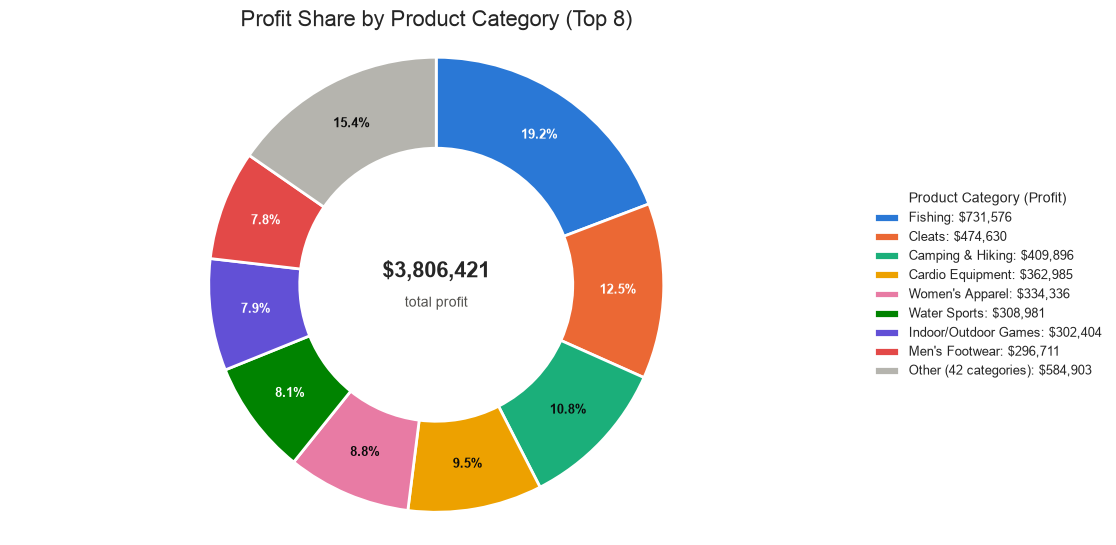

In [4]:
top_n = 8

top_categories = profit_per_product_category.head(top_n)
other_profit = profit_per_product_category.iloc[top_n:].sum()
other_count = len(profit_per_product_category) - top_n

donut_data = pd.concat([top_categories, pd.Series({f'Other ({other_count} categories)': other_profit})])

colors = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948', '#b5b4ae']

legend_labels = [
    f'{category}: ${profit:,.0f}'
    for category, profit in donut_data.items()
]

fig, ax = plt.subplots(figsize=(11, 6.5))

wedges, _, pct_labels = ax.pie(
    donut_data,
    startangle=90,
    counterclock=False,
    colors=colors,
    autopct='%1.1f%%',
    pctdistance=0.8,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2, 'width': 0.4}
)

light_colors = {'#1baf7a', '#eda100', '#e87ba4', '#b5b4ae'}

for label, color in zip(pct_labels, colors):
    label.set_fontsize(9)
    label.set_fontweight('bold')
    label.set_color('#0b0b0b' if color in light_colors else 'white')

ax.text(0, 0.06, f'${total_profit:,.0f}', ha='center', va='center', fontsize=16, fontweight='bold')
ax.text(0, -0.08, 'total profit', ha='center', va='center', fontsize=10, color='#52514e')

ax.legend(
    wedges,
    legend_labels,
    title='Product Category (Profit)',
    loc='center left',
    bbox_to_anchor=(1, 0.5),
    frameon=False
)

ax.set_title('Profit Share by Product Category (Top 8)', fontsize=16)
ax.axis('equal')

plt.savefig('../visualizations/profit-share-by-product-category.png', bbox_inches='tight')
plt.show()

## How do discounts affect profit margins?

In [5]:
df['is_at_loss'] = df['order_item_profit'] < 0

discount_rates = df.groupby('order_item_discount_rate').agg(
    profit=('order_item_profit', 'sum'),
    revenue=('order_item_total', 'sum'),
    number_of_items=('order_item_profit', 'count'),
    sold_at_loss=('is_at_loss', 'mean')
).reset_index()

discount_rates['margin'] = discount_rates['profit'] / discount_rates['revenue']

discount_rates_styled = discount_rates.style.format({
    'order_item_discount_rate': '{:.2%}',
    'profit': '${:,.0f}',
    'revenue': '${:,.0f}',
    'sold_at_loss': '{:.2%}',
    'margin': '{:.2%}'
})

discount_rates_styled

,order_item_discount_rate,profit,revenue,number_of_items,sold_at_loss,margin
0,0.00%,"$254,643","$1,966,128",9640,18.57%,12.95%
1,1.00%,"$230,031","$1,939,481",9620,18.44%,11.86%
2,2.00%,"$229,354","$1,920,662",9611,18.22%,11.94%
3,3.00%,"$213,001","$1,884,589",9556,19.15%,11.30%
4,4.00%,"$220,282","$1,875,444",9597,18.93%,11.75%
5,5.00%,"$233,075","$1,862,528",9619,18.60%,12.51%
6,6.00%,"$228,671","$1,850,839",9614,18.14%,12.35%
7,7.00%,"$224,308","$1,818,642",9588,18.87%,12.33%
8,9.00%,"$219,801","$1,782,309",9597,18.10%,12.33%
9,10.00%,"$209,691","$1,760,249",9587,18.30%,11.91%


### Conclusion

Across all 18 discount levels, the *margin* stays between 11.1% and 12.95%. The small differences between neighbouring levels go both up and down, so they look like noise rather than a trend.

The cost of a product doesn't change when it is sold at a discount, so every dollar of discount should come straight out of profit. The 0% and 25% groups are easy to compare, because before the discount they sold almost the same amount (\$1,966,128 vs \$1,952,443). The 25% discount took \$488,133 off that group's revenue, but its profit is only \$66,544 lower than the no-discount group (\$188,099 vs \$254,643). If the product cost stayed the same, a discount that large would have wiped out the group's entire profit.

Even with no discount, 18.57% of items are sold at a loss. Across all discount levels the share stays between 18.1% and 19.59%, with no upward trend. If discounts were pushing items below their cost, this share would rise as the discount gets bigger. So the losses in this dataset are not caused by discounts.

In this dataset, profit seems to be recorded as a roughly fixed share of the price the customer actually paid, whatever the discount. The real cost of discounting is not visible in the data. Together with the almost identical number of items at every discount level (about 9,600 each), this is more evidence that the data is synthetic. So this analysis cannot measure how discounts affect margins in practice.

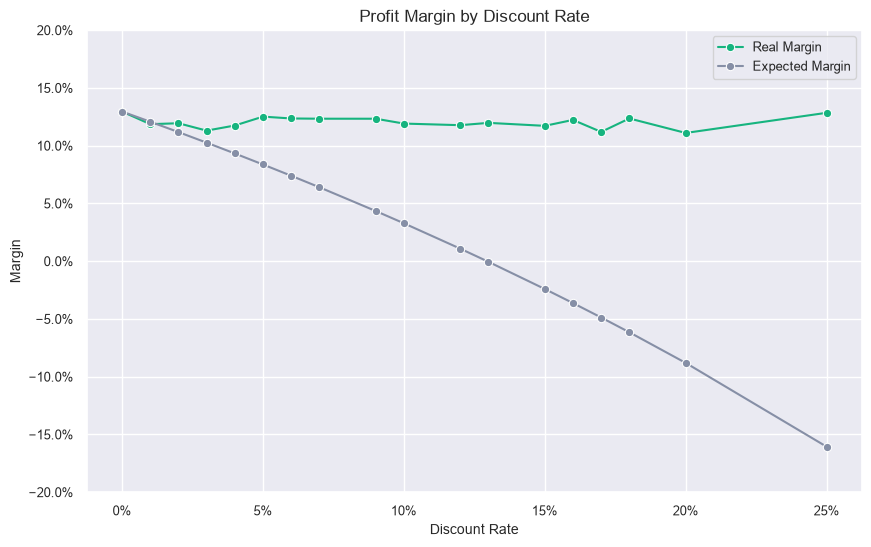

In [6]:
import matplotlib.ticker as mtick

discount_rates['expected_margin'] = (discount_rates.iloc[0]['margin'] - discount_rates['order_item_discount_rate']) / (1 - discount_rates['order_item_discount_rate'])

plt.figure(figsize=(10, 6))

g = sns.lineplot(
    data=discount_rates,
    x='order_item_discount_rate',
    y='margin',
    color='#16B47F',
    marker='o',
    label='Real Margin'
)

g = sns.lineplot(
    data=discount_rates,
    x='order_item_discount_rate',
    y='expected_margin',
    color='#868FA6',
    marker='o',
    label='Expected Margin'
)


g.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0))
g.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0, decimals=0))
plt.ylim(-0.2, 0.2)

plt.title('Profit Margin by Discount Rate')
plt.xlabel('Discount Rate')
plt.ylabel('Margin')
plt.legend()

plt.savefig('../visualizations/profit-margin-by-discount-rate.png', bbox_inches='tight')
plt.show()

## Which customer segments contribute most to revenue and profit?

In [7]:
profit_per_customer_segment = df.groupby('customer_segment')['order_item_profit'].sum()

print(f'Total profit: ${total_profit:,.0f}')

for segment, profit in profit_per_customer_segment.items():
    print(f'{segment}: ${profit:,.0f} ({(profit / total_profit):,.2%} of global profit)')

Total profit: $3,806,421
Consumer: $1,982,864 (52.09% of global profit)
Corporate: $1,157,821 (30.42% of global profit)
Home Office: $665,736 (17.49% of global profit)


In [8]:
revenue_per_customer_segment = df.groupby('customer_segment')['order_item_total'].sum()
total_revenue = df['order_item_total'].sum()

print(f'Total revenue: ${total_revenue:,.0f}')

for segment, revenue in revenue_per_customer_segment.items():
    print(f'{segment}: ${revenue:,.0f} ({(revenue / total_revenue):,.2%} of global revenue)')

Total revenue: $31,644,665
Consumer: $16,417,550 (51.88% of global revenue)
Corporate: $9,621,052 (30.40% of global revenue)
Home Office: $5,606,064 (17.72% of global revenue)


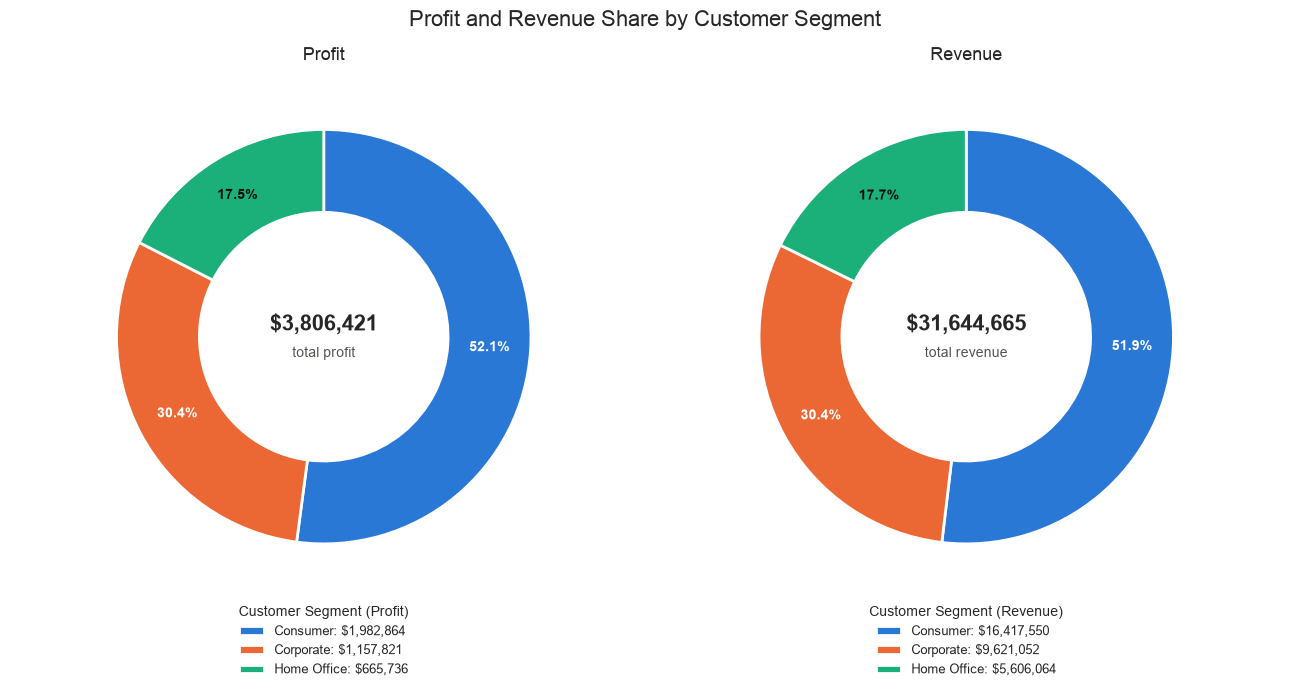

In [9]:
segment_order = profit_per_customer_segment.sort_values(ascending=False).index
segment_colors = {'Consumer': '#2a78d6', 'Corporate': '#eb6834', 'Home Office': '#1baf7a'}
light_colors = {'#1baf7a'}

charts = [
    ('Profit', profit_per_customer_segment.reindex(segment_order), total_profit),
    ('Revenue', revenue_per_customer_segment.reindex(segment_order), total_revenue),
]

fig, axes = plt.subplots(1, 2, figsize=(13, 7))

for ax, (metric, values, total) in zip(axes, charts):
    colors = [segment_colors[segment] for segment in values.index]

    wedges, _, pct_labels = ax.pie(
        values,
        startangle=90,
        counterclock=False,
        colors=colors,
        autopct='%1.1f%%',
        pctdistance=0.8,
        wedgeprops={'edgecolor': 'white', 'linewidth': 2, 'width': 0.4}
    )

    for label, color in zip(pct_labels, colors):
        label.set_fontsize(10)
        label.set_fontweight('bold')
        label.set_color('#0b0b0b' if color in light_colors else 'white')

    ax.text(0, 0.06, f'${total:,.0f}', ha='center', va='center', fontsize=16, fontweight='bold')
    ax.text(0, -0.08, f'total {metric.lower()}', ha='center', va='center', fontsize=10, color='#52514e')

    ax.legend(
        wedges,
        [f'{segment}: ${value:,.0f}' for segment, value in values.items()],
        title=f'Customer Segment ({metric})',
        loc='upper center',
        bbox_to_anchor=(0.5, 0.02),
        frameon=False
    )

    ax.set_title(metric, fontsize=13)
    ax.axis('equal')

fig.suptitle('Profit and Revenue Share by Customer Segment', fontsize=16)

plt.tight_layout()

plt.savefig('../visualizations/profit-and-revenue-share-by-customer-segment.png', bbox_inches='tight')
plt.show()